In [176]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
import seaborn as sns
import matplotlib.ticker as mticker
from matplotlib import ticker

from eda_data import *

# Module 1: Foundations

Use the object-oriented (OO) API — fig, ax = plt.subplots() then ax.method() — for everything beyond a throwaway plot. The pyplot state machine (plt.plot, plt.title) acts on an invisible "current axes", which breaks the moment you have more than one panel or call plotting code from a function.
The object hierarchy. Every chart is a tree of Artist objects:
1. Figure — the whole canvas; owns size, DPI, suptitle, and one or more Axes.
2. Axes — one plotting area with its own data coordinates. Almost all your work happens here.
3. Axis (ax.xaxis, ax.yaxis) — the ticks, tick labels, and scale for one direction.
4. Primitives — Line2D, PathCollection (scatter), Rectangle (bars), Text, Patch. Each is returned when you plot, so you can modify it later.

In [18]:
x = np.linspace(0,10,200)

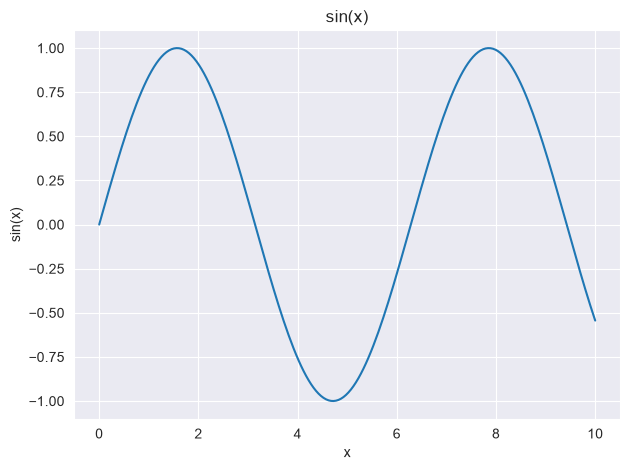

In [25]:
# Pyplot style — fine in a REPL, fragile in code
plt.plot(x,np.sin(x))
plt.title("sin(x)")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.tight_layout()
plt.show()

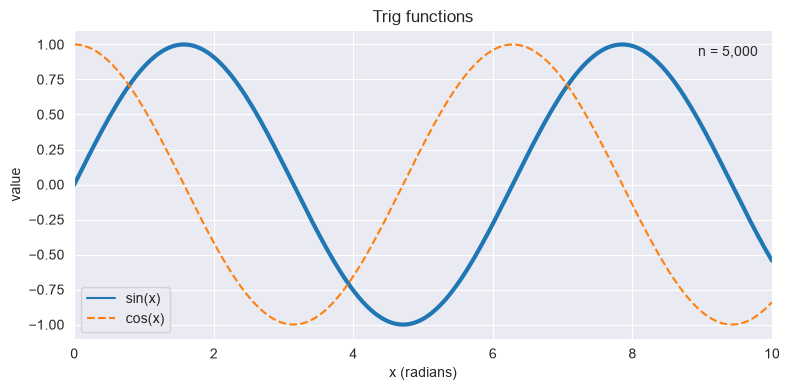

In [49]:
# OO style - explicit, composable , testable
fig,ax = plt.subplots(figsize=(8,4),dpi=100)

line, = ax.plot(x, np.sin(x),label="sin(x)") # Note the trailing comma: plot returns a list

ax.plot(x, np.cos(x),label="cos(x)",linestyle="--")

ax.set(
    title="Trig functions",
    xlabel="x (radians)",
    ylabel="value",
    xlim=(0,10),
)
ax.legend()
ax.text(0.98, 0.95, "n = 5,000", transform=ax.transAxes, ha="right", va="top")
line.set_linewidth(3) # Modify an artist after creation
fig.tight_layout()
plt.show()

# Module 2: Core plot types

Pick the chart from the question, not the data type:
  * for trend use line chart
  * for relationship  use scatter chart
  * for comparison across categories  use bar chart
  * for distribution  use these charts histogram/box/violin
  * for composition use these charts stacked bar
  almost never pie chart.

Questions

1. How does a value change over time?
     - Method use ax.plot
     - Key parameters  are marker, linestyle, drawstyle="steps-post"

2. How do numeric variables relate?
    - Method use ax.scatter
    - Key parameters use s(size), c + cmap (colour by value), alpha

3. How do categories compare?
    - Method use ax.bar or ax.barh
    - Key parameters width, bottom (stacking), yerr

4. What is the shape of a distribution?
    - Method use *ax.hist*
    - Key parameters bins, density, histtype="step", cummulative

5. Median, spread, outliers per group?
    - Method use ax.boxplot
    - Key parameters tick_labels, showfliers, whis

6. Full distribution shape per group?
    - Method use ax.violinplot
    - Key parameters showmedians, bw_method

7. Uncertainty band around a line?
    - Method use ax.fill_between
    - Key parameters alpha, where

8. Value with error?
    - Method use ax.errorbar
    - Key parameters yerr, capsize, fmt

9. Matrix of values?
    - Method use ax.imshow/axpcolormesh
    - Key parameters cmap, vmin/vmax, aspect

In [52]:
df = make_churn()


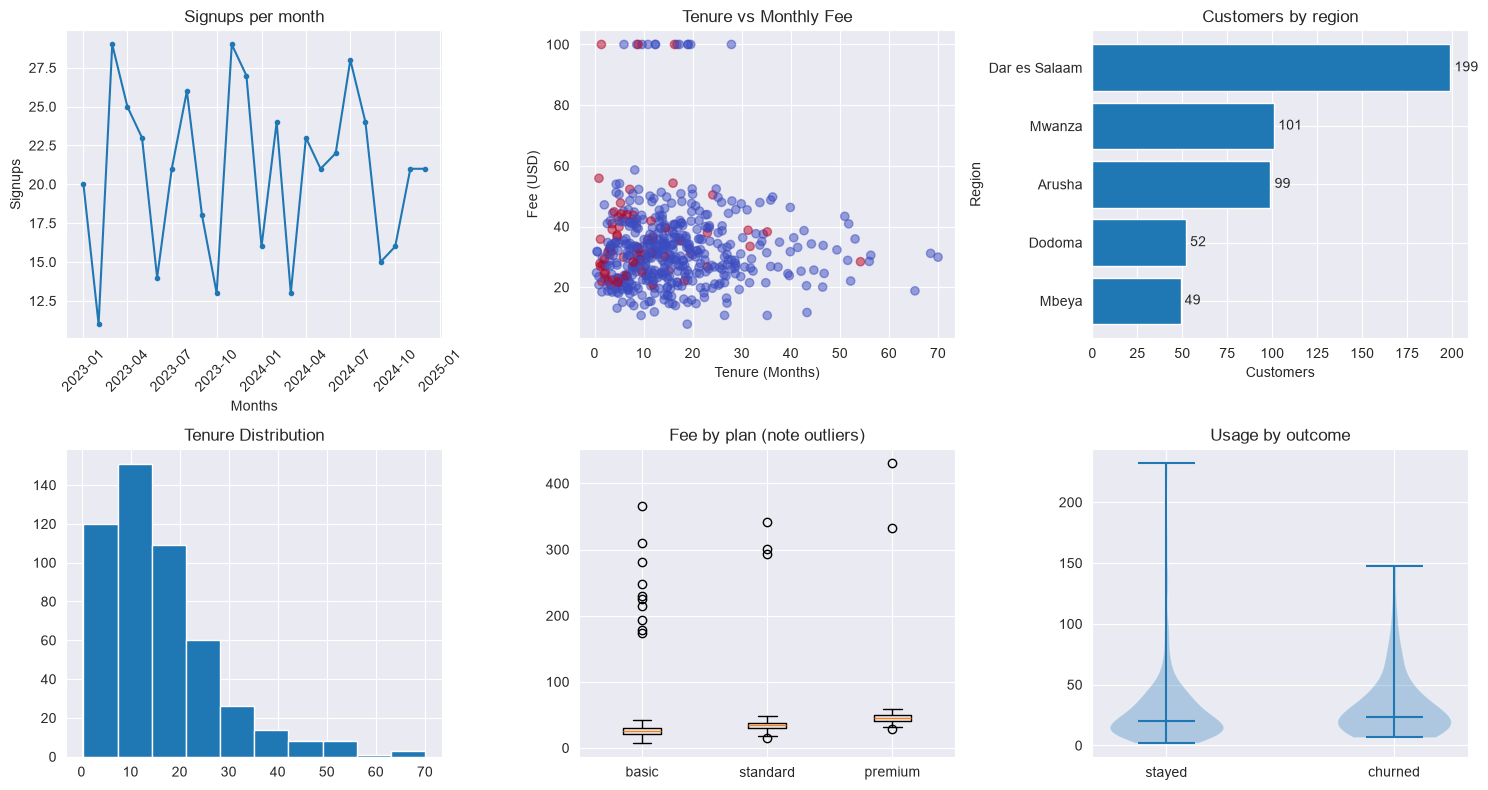

In [132]:
fig, axs = plt.subplots(2,3, figsize=(15,8))

#1. Line: Monthly signup
monthly = df.set_index("signup").resample("MS").size()
axs[0,0].plot(monthly.index,monthly.values, marker="o",ms=3)
axs[0,0].tick_params(axis="x", rotation=45)
# axs[0,0].set(title="Signups per month")
axs[0,0].set(title="Signups per month", xlabel="Months", ylabel="Signups")

#2. Scatter: Tenure vs fee, colored by churn
sc = axs[0,1].scatter(
    df.tenure,
    df.monthly_fee.clip(upper=100),
    c=df.churned,
    cmap="coolwarm",
    alpha=0.5,
)
axs[0,1].set(title="Tenure vs Monthly Fee", xlabel="Tenure (Months)", ylabel="Fee (USD)")

#3. Horizontal bar: customers per region, sorted
counts = df.region.value_counts().sort_values()
axs[0,2].barh(counts.index,counts.values)
axs[0,2].bar_label(axs[0,2].containers[0], padding=3)
axs[0,2].set_title("Customers by region")
axs[0,2].set_ylabel("Region")
axs[0,2].set_xlabel("Customers")

# 4. Histogram skewed tenure
axs[1,0].hist(df.tenure, bins=10,edgecolor="white")
axs[1,0].set_title("Tenure Distribution")

# 5. Box plot : fee by plan
plans = ["basic", "standard", "premium"]
axs[1,1].boxplot([df.loc[df.plan == p, "monthly_fee"] for p in plans],tick_labels=plans)
axs[1,1].set(title="Fee by plan (note outliers)")

# 6. Violin: usage by churn (drop NaN first  - violinplot can't handle them)
data = [df.loc[df.churned == k,"usage_gb"].dropna() for k in (0,1)]

axs[1,2].violinplot(data,showmedians=True)
axs[1,2].set_xticks([1,2],["stayed","churned"])
axs[1,2].set_title("Usage by outcome")
plt.tight_layout()

# Module 3: Customization

A good EDA chart answers its question in under five seconds: one highlighted message, everything else muted, units on every axis. Customization is how you get there.

### Color and colormaps - choose by data types



<BarContainer object of 5 artists>

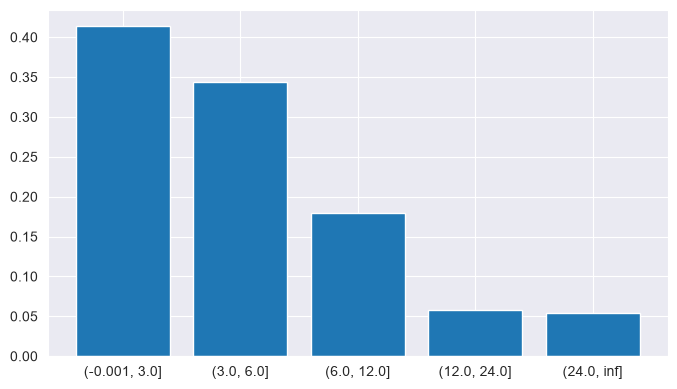

In [168]:

bands = pd.cut(df.tenure,[0,3,6,12,24,np.inf], include_lowest=True)
rates = df.groupby(bands, observed=True)['churned'].mean()

fig, ax = plt.subplots(figsize=(8,4.5))
ax.bar(rates.index.astype(str),rates.values)

### Look at what you get and list what's wrong:

    • x labels read (-0.001, 3.0] — correct but ugly.
    • y-axis shows 0.05, 0.10 … — the reader has to convert to percent in their head.
    • No axis titles, so nobody knows the units.
    • All bars are the same blue, so nothing tells the eye where to look.
    • No title, and no statement of what the chart shows.
Each step below fixes one of these.

#### Step 1: Readable labels and units

[Text(0.5, 0, 'Tenure (Months)'), Text(0, 0.5, 'Churn Rate')]

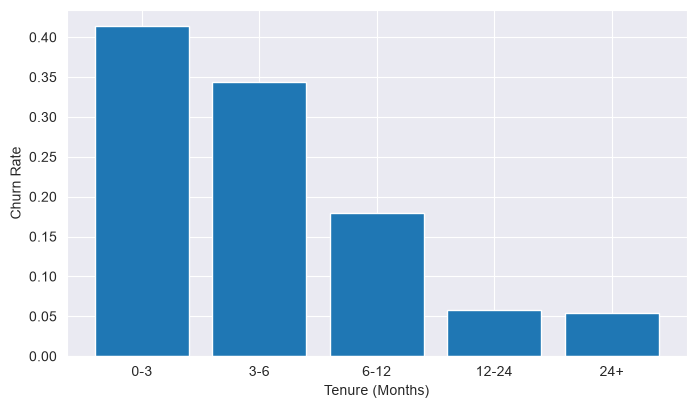

In [172]:
bands = pd.cut(
    df.tenure,
    [0,3,6,12,24,np.inf],
    include_lowest=True,
    labels=["0-3", "3-6","6-12","12-24","24+"]
)
rates = df.groupby(bands, observed=True)['churned'].mean()

fig, ax = plt.subplots(figsize=(8,4.5))
ax.bar(rates.index.astype(str),rates.values)
ax.set(xlabel="Tenure (Months)", ylabel="Churn Rate")

#### Step 2 — Show the y-axis as percentages

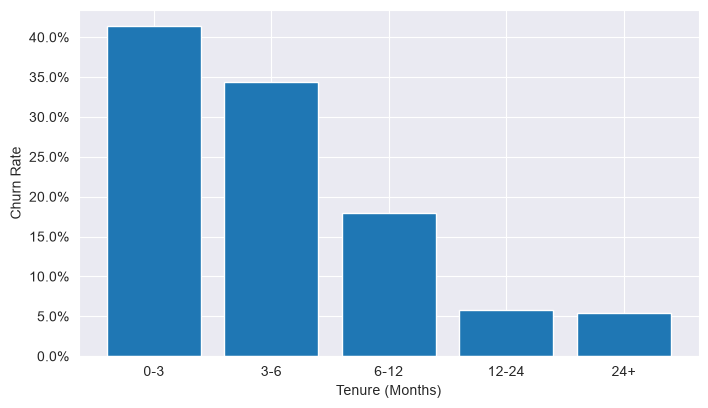

In [186]:
bands = pd.cut(
    df.tenure,
    [0,3,6,12,24,np.inf],
    include_lowest=True,
    labels=["0-3", "3-6","6-12","12-24","24+"]
)
rates = df.groupby(bands, observed=True)['churned'].mean()

fig, ax = plt.subplots(figsize=(8,4.5))
ax.bar(rates.index.astype(str),rates.values)
ax.set(xlabel="Tenure (Months)", ylabel="Churn Rate")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

#### Step 3 — Colour one bar, grey the rest

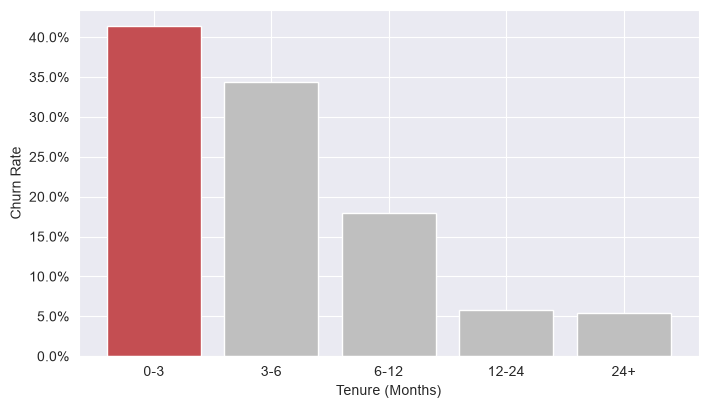

In [191]:
bands = pd.cut(
    df.tenure,
    [0,3,6,12,24,np.inf],
    include_lowest=True,
    labels=["0-3", "3-6","6-12","12-24","24+"]
)
rates = df.groupby(bands, observed=True)['churned'].mean()

fig, ax = plt.subplots(figsize=(8,4.5))
colors = ["#c44e52"] + ["0.75"] * (len(rates)-1)
bars = ax.bar(rates.index.astype(str),rates.values, color=colors)
ax.set(xlabel="Tenure (Months)", ylabel="Churn Rate")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

#### Step 4 — A title that states the finding, and less clutter

A title like "Churn by tenure" repeats the axis labels. A title that states the result tells the reader what to conclude:

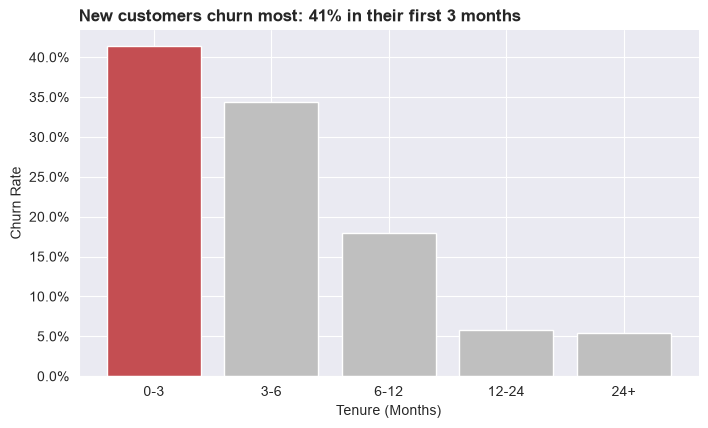

In [201]:
bands = pd.cut(
    df.tenure,
    [0,3,6,12,24,np.inf],
    include_lowest=True,
    labels=["0-3", "3-6","6-12","12-24","24+"]
)
rates = df.groupby(bands, observed=True)['churned'].mean()

fig, ax = plt.subplots(figsize=(8,4.5))
colors = ["#c44e52"] + ["0.75"] * (len(rates)-1)
bars = ax.bar(rates.index.astype(str),rates.values, color=colors)
ax.set(xlabel="Tenure (Months)", ylabel="Churn Rate")
ax.set_title(f"New customers churn most: {rates.iloc[0]:.0%} in their first 3 months", loc="left", fontweight="bold")
ax.spines[["top","right"]].set_visible(False)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

#### Step 5 — Exact values and a reference line

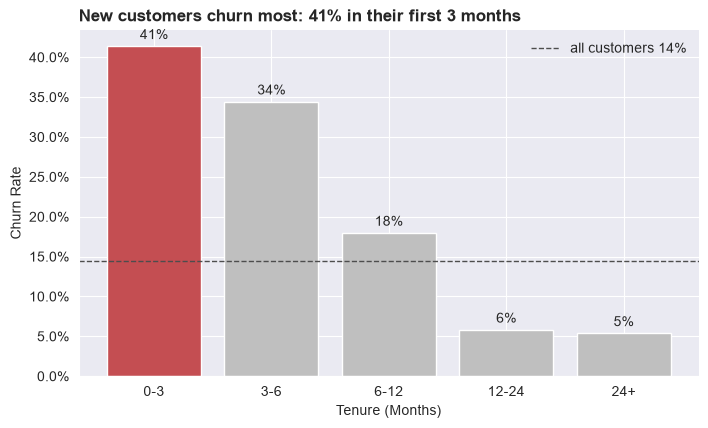

In [209]:
bands = pd.cut(
    df.tenure,
    [0,3,6,12,24,np.inf],
    include_lowest=True,
    labels=["0-3", "3-6","6-12","12-24","24+"]
)
rates = df.groupby(bands, observed=True)['churned'].mean()


fig, ax = plt.subplots(figsize=(8,4.5))
colors = ["#c44e52"] + ["0.75"] * (len(rates)-1)
bars = ax.bar(rates.index.astype(str),rates.values, color=colors)

overall = df['churned'].mean()
ax.bar_label(bars, labels=[f"{v:.0%}" for v in rates], padding=3)
ax.axhline(overall, color="0.3", ls="--",lw=1, label=f"all customers {overall:.0%}")

ax.set(xlabel="Tenure (Months)", ylabel="Churn Rate")
ax.set_title(f"New customers churn most: {rates.iloc[0]:.0%} in their first 3 months", loc="left", fontweight="bold")
ax.spines[["top","right"]].set_visible(False)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(frameon=False)

#### Step 6 — Point at the key fact with an annotation


ax.annotate draws text with an arrow. It needs two positions: xy is the point the arrow touches, xytext is where the text sits. On a bar chart, the bars sit at x = 0, 1, 2, 3, 4 and each is 0.8 wide, so the top-right corner of the first bar is (0.4, rates.iloc[0]).

Text(1.5, 0.3724137931034483, '7.7× the rate of\ncustomers past 2 years')

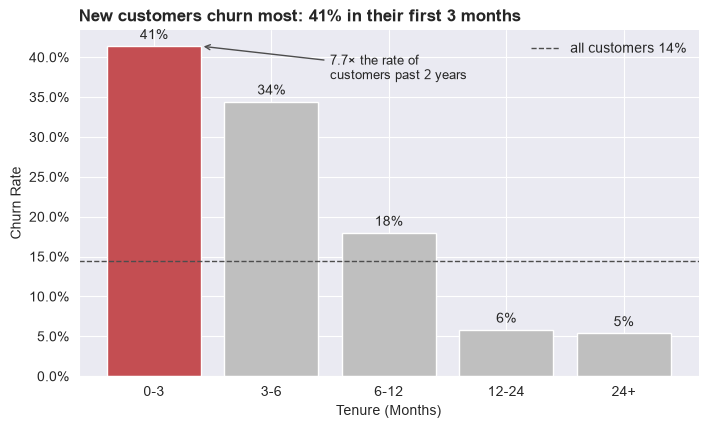

In [213]:
bands = pd.cut(
    df.tenure,
    [0,3,6,12,24,np.inf],
    include_lowest=True,
    labels=["0-3", "3-6","6-12","12-24","24+"]
)
rates = df.groupby(bands, observed=True)['churned'].mean()


fig, ax = plt.subplots(figsize=(8,4.5))
colors = ["#c44e52"] + ["0.75"] * (len(rates)-1)
bars = ax.bar(rates.index.astype(str),rates.values, color=colors)

overall = df['churned'].mean()
ax.bar_label(bars, labels=[f"{v:.0%}" for v in rates], padding=3)
ax.axhline(overall, color="0.3", ls="--",lw=1, label=f"all customers {overall:.0%}")

ax.set(xlabel="Tenure (Months)", ylabel="Churn Rate")
ax.set_title(f"New customers churn most: {rates.iloc[0]:.0%} in their first 3 months", loc="left", fontweight="bold")
ax.spines[["top","right"]].set_visible(False)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(frameon=False)

ratio = rates.iloc[0] / rates.iloc[-1]
ax.annotate(f"{ratio:.1f}× the rate of\ncustomers past 2 years",
            xy=(0.4, rates.iloc[0]),                     # arrow tip: top of the first bar
            xytext=(1.5, rates.iloc[0] * 0.9),           # text: to the right, a little lower
            arrowprops=dict(arrowstyle="->", color="0.3"), fontsize=9)

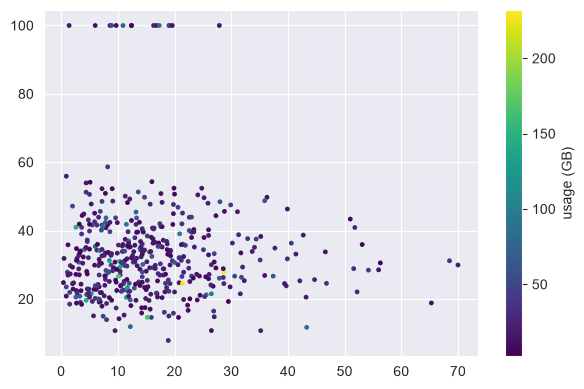

In [216]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(df.tenure, df.monthly_fee.clip(upper=100), c=df.usage_gb, cmap="viridis", s=6)
fig.colorbar(sc, ax=ax, label="usage (GB)")

Text(0.0, 1.0, 'ConciseDateFormatter: year printed once, months short')

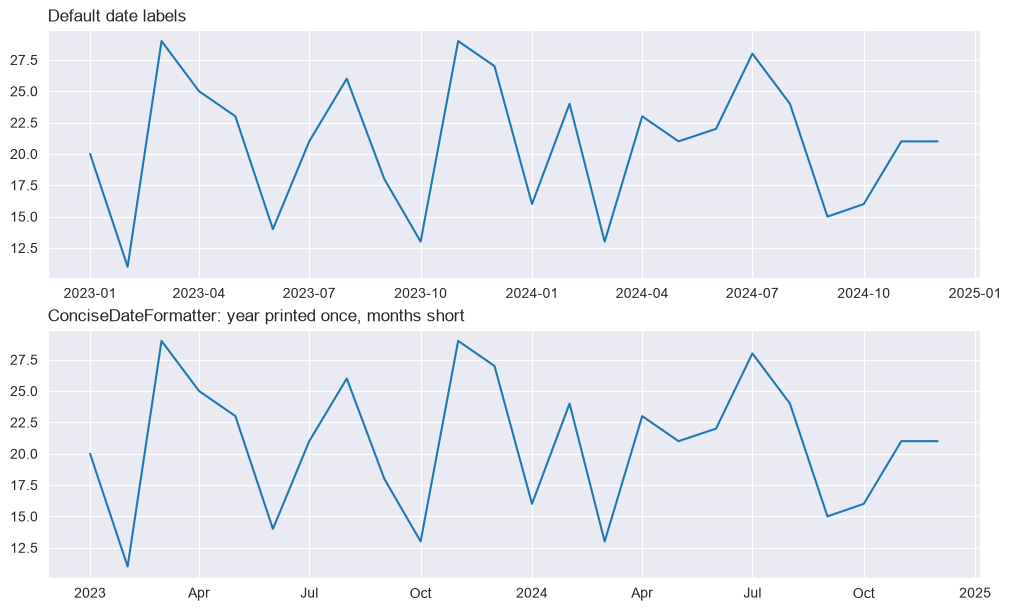

In [217]:
monthly = df.set_index("signup").resample("MS").size()
fig, axs = plt.subplots(2, 1, figsize=(10, 6), layout="constrained")

axs[0].plot(monthly.index, monthly.values)
axs[0].set_title("Default date labels", loc="left")

import matplotlib.dates as mdates
axs[1].plot(monthly.index, monthly.values)
loc = mdates.AutoDateLocator()                          # decides WHERE date ticks go
axs[1].xaxis.set_major_locator(loc)
axs[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))   # decides WHAT they say
axs[1].set_title("ConciseDateFormatter: year printed once, months short", loc="left")

# Module 4: Layouts

A layout is how you place several charts on one image.
Think of the Figure as a sheet of paper and each Axes as one chart drawn on it. So far every sheet held one chart; in real EDA you put 2–6 related charts on one sheet so they can be compared at a glance.
We'll build up from the simplest case. All code assumes the imports and df from Module 3, Step 0.

#### Step 1 — A grid of equal charts

Text(0.5, 1.0, 'Support tickets')

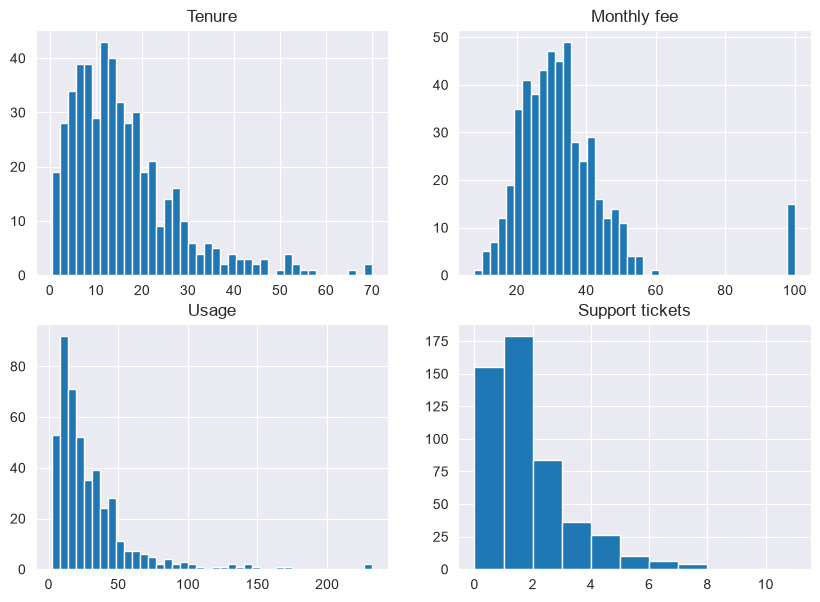

In [220]:
fig, axs = plt.subplots(2, 2, figsize=(10, 7))

axs[0, 0].hist(df.tenure, bins=40)            # row 0, column 0 = top-left
axs[0, 0].set_title("Tenure")
axs[0, 1].hist(df.monthly_fee.clip(upper=100), bins=40)   # row 0, column 1 = top-right
axs[0, 1].set_title("Monthly fee")
axs[1, 0].hist(df.usage_gb.dropna(), bins=40)  # row 1, column 0 = bottom-left
axs[1, 0].set_title("Usage")
axs[1, 1].hist(df.support_tickets, bins=range(0, 12))     # bottom-right
axs[1, 1].set_title("Support tickets")

 To fill a grid in a loop flatten it first

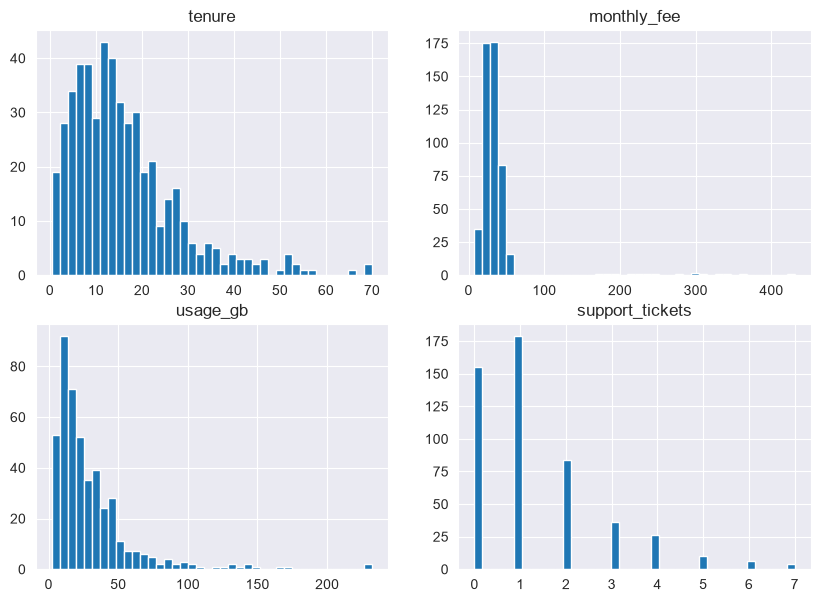

In [232]:
fig, axs = plt.subplots(2,2, figsize=(10,7))
for ax, col in zip(axs.flat, ["tenure","monthly_fee","usage_gb","support_tickets"]):
    ax.hist(df[col].dropna(),bins=40)
    ax.set_title(f"{col}")

Step2 Stop lavel from overraping

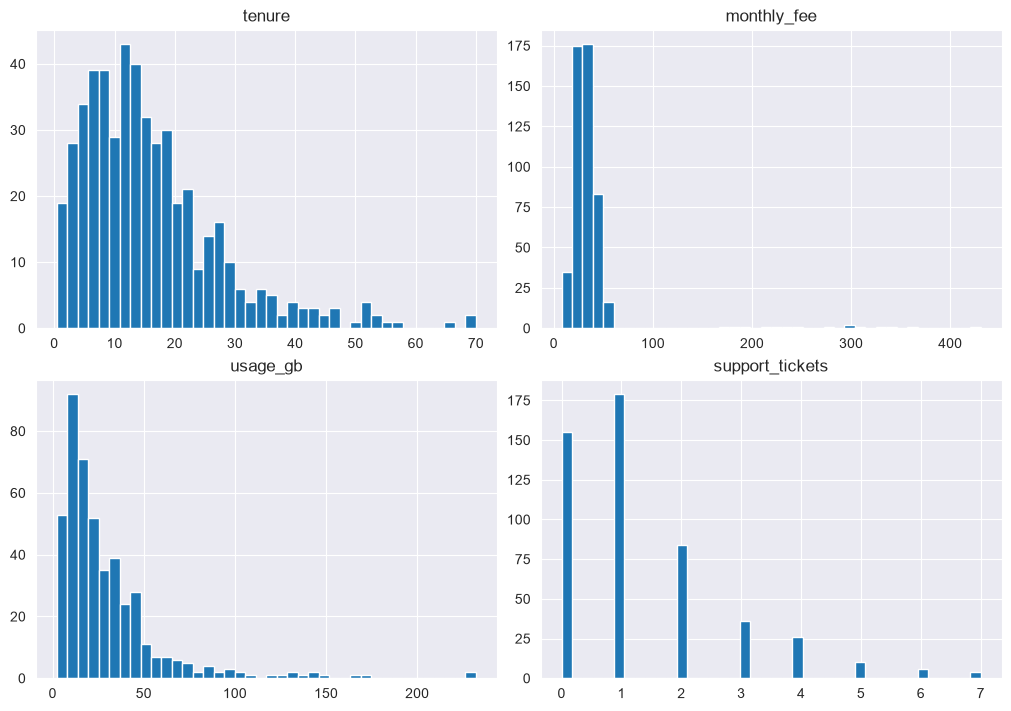

In [234]:
fig, axs = plt.subplots(2,2, figsize=(10,7), layout="constrained")
for ax, col in zip(axs.flat, ["tenure","monthly_fee","usage_gb","support_tickets"]):
    ax.hist(df[col].dropna(),bins=40)
    ax.set_title(f"{col}")

#### Step 3 — Shared axes for fair comparison

Suppose you compare tenure for customers who stayed vs those who left. If each chart picks its own x range, the shapes look similar even when they aren't. sharex=True forces both charts to use the same x range, so you compare like with like:


Text(0.5, 0, 'tenure (months)')

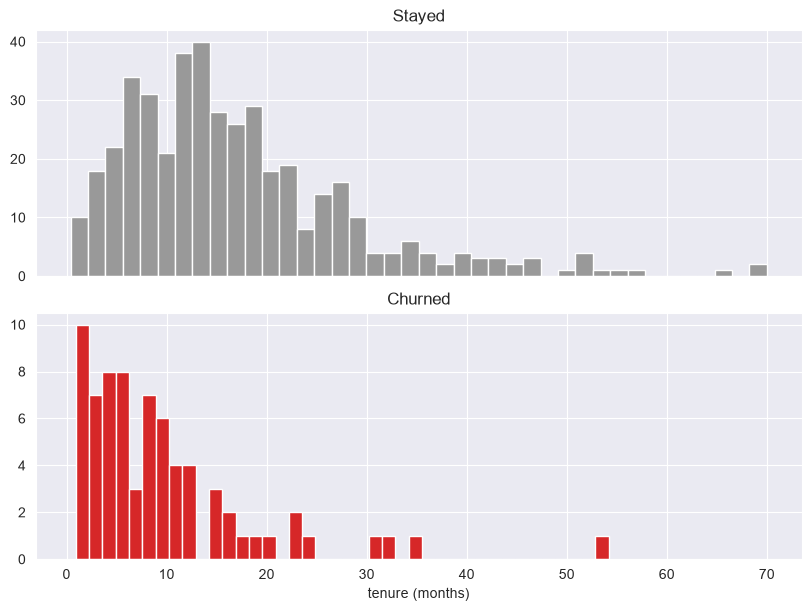

In [236]:
fig, axs = plt.subplots(2, 1, figsize=(8, 6), sharex=True, layout="constrained")

axs[0].hist(df.loc[df.churned == 0, "tenure"], bins=40, color="0.6")
axs[0].set_title("Stayed")

axs[1].hist(df.loc[df.churned == 1, "tenure"], bins=40, color="C3")
axs[1].set_title("Churned")
axs[1].set_xlabel("tenure (months)")

Now it's obvious that churners cluster at low tenure. Notice the top chart lost its x tick labels: they'd be identical to the bottom ones, so Matplotlib hides them. sharey=True does the same for the vertical axis.

#### Step 4 — Charts of different sizes (subplot_mosaic)

["hist",    "hist",    "box"]     ← "hist" spans two columns, "box" takes one

["scatter", "scatter", "bar"]     ← "scatter" spans two columns, "bar" takes one

Text(0.5, 0.98, 'Tenure overview')

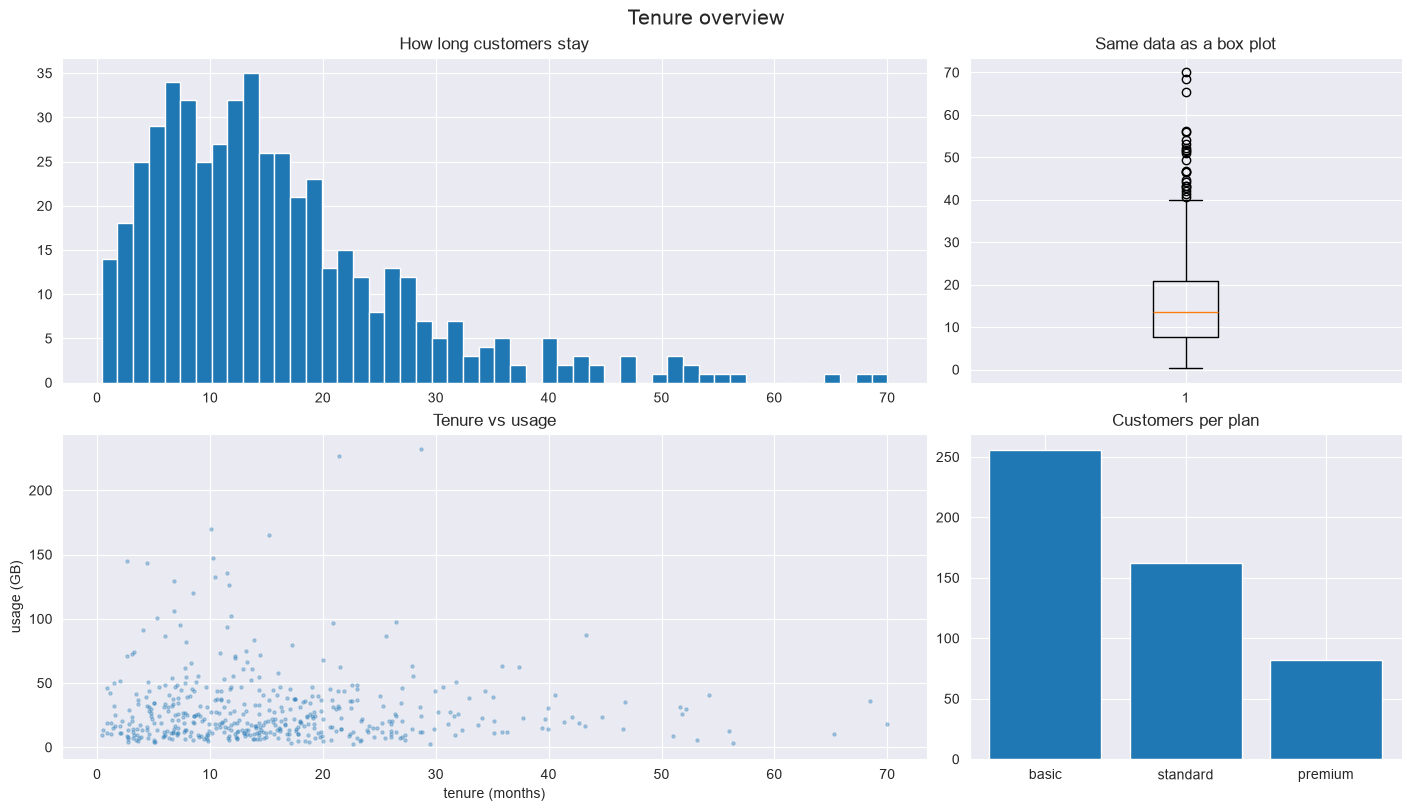

In [237]:
fig, ax = plt.subplot_mosaic(
    [["hist", "hist", "box"],
     ["scatter", "scatter", "bar"]],
    figsize=(14, 8), layout="constrained")

ax["hist"].hist(df.tenure, bins=50)
ax["hist"].set_title("How long customers stay")

ax["box"].boxplot(df.tenure)
ax["box"].set_title("Same data as a box plot")

ax["scatter"].scatter(df.tenure, df.usage_gb, s=5, alpha=0.3)
ax["scatter"].set(title="Tenure vs usage", xlabel="tenure (months)", ylabel="usage (GB)")

plan_counts = df.plan.value_counts()
ax["bar"].bar(plan_counts.index, plan_counts.values)
ax["bar"].set_title("Customers per plan")
fig.suptitle("Tenure overview", fontsize=15)    # one title for the whole sheet

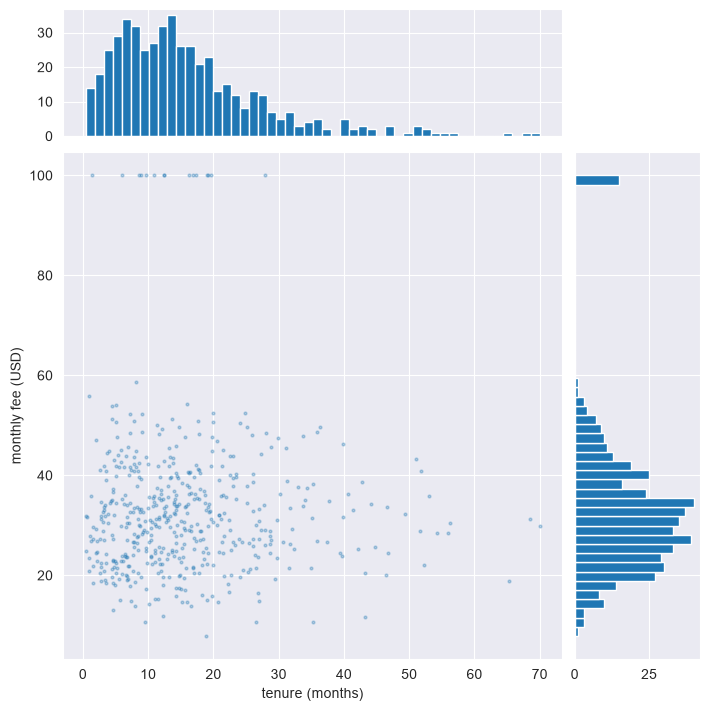

In [238]:
fig, ax = plt.subplot_mosaic(
    [["top", "."],
     ["main", "right"]],
    figsize=(7, 7), layout="constrained",
    width_ratios=[4, 1], height_ratios=[1, 4])     # main chart is 4× bigger than the edges

x, y = df.tenure, df.monthly_fee.clip(upper=100)
ax["main"].scatter(x, y, s=4, alpha=0.3)
ax["main"].set(xlabel="tenure (months)", ylabel="monthly fee (USD)")
ax["top"].hist(x, bins=50)
ax["right"].hist(y, bins=50, orientation="horizontal")   # sideways histogram
ax["top"].sharex(ax["main"])        # line up with the main chart
ax["right"].sharey(ax["main"])
ax["top"].tick_params(labelbottom=False)    # hide duplicate labels
ax["right"].tick_params(labelleft=False)